# Privacy vs Utility

## Setup

Loads the paired Offline and On-Demand results for one evaluation run. Set `RUN_FOLDER` below to the run you want to analyze. It points to `data/output/<RUN_FOLDER>/`.

In [1]:
from pathlib import Path

import pandas as pd


STRATEGY_OFFLINE = "offline"
STRATEGY_ONDEMAND = "ondemand"

# TODO: Update path for evaluation
RUN_FOLDER = "20260703_095808"
print("Evaluation run folder:", RUN_FOLDER)


_cwd = Path.cwd().resolve()
REPO_ROOT = _cwd if (_cwd / "pyproject.toml").is_file() else _cwd.parent
assert (REPO_ROOT / "pyproject.toml").is_file(), "Run Jupyter from repo root or notebooks/."

eval_run_dir = (REPO_ROOT / "data" / "output" / RUN_FOLDER).resolve()
paths = sorted(eval_run_dir.glob("results_*.jsonl"))
assert paths, f"No results_*.jsonl in {eval_run_dir}"
df = pd.concat([pd.read_json(path, lines=True) for path in paths], ignore_index=True)
display(df.head())

offline_df = df[df["strategy"] == STRATEGY_OFFLINE].copy()
ondemand_df = df[df["strategy"] == STRATEGY_ONDEMAND].copy()
assert not offline_df.empty, "Expected offline rows"
assert not ondemand_df.empty, "Expected on-demand rows"

paired = offline_df.merge(
    ondemand_df,
    on="question_id",
    suffixes=("_offline", "_ondemand"),
    validate="one_to_one",
)
print(f"Total paired questions (question_id)={len(paired)}")
display(paired[["question_id", "strategy_offline", "strategy_ondemand"]].head())

Evaluation run folder: 20260703_095808


,run_id,strategy,question_id,question,ground_truth,llm_model,judge_model,raw_answer,final_answer,answer_is_refusal,contexts,doc_ids,dataset,total_pii,leaked_pii,leakage_rate,faithfulness,context_precision,context_recall,factual_correctness
0,51f7d2e4,offline,q01,In ECHR case 001-80593 (application no. 47297/...,The PKK (the Kurdistan Workers' Party).,qwen3.6:27b,gemma4:26b,"Based on the provided context, it is **not pos...","Based on the provided context, it is **not pos...",True,[PROCEDURE\n\nThe case originated in an applic...,"[001-102371, 001-61712, 001-79486]",train,111,2,0.018018,NaN,NaN,NaN,0.0
1,51f7d2e4,offline,q02,In ECHR case 001-59335 (application no. 29851/...,The People's Labour Party (Halkın Emek Partisi...,qwen3.6:27b,gemma4:26b,"Based on the provided context, the text does n...","Based on the provided context, the text does n...",True,[The applicant and the Government each filed o...,"[001-59335, 001-60940, 001-59674]",train,146,4,0.027397,NaN,NaN,NaN,0.0
2,51f7d2e4,offline,q03,In ECHR case 001-90194 (application no. 36244/...,The Leave to Appeal Board (Procesbevillingsnæv...,qwen3.6:27b,gemma4:26b,"Based on the provided context, the body that g...","Based on the provided context, the body that g...",False,[On <DATE_TIME> the Appeals Permission Board (...,"[001-179218, 001-91899, 001-57891]",train,216,0,0.000000,1.0,1.0,1.0,0.0
3,51f7d2e4,offline,q04,In ECHR case 001-84741 (application no. 29366/...,The Ministry of Foreign Affairs.,qwen3.6:27b,gemma4:26b,"Based on the provided context, it is not possi...","Based on the provided context, it is not possi...",True,[PROCEDURE\n\nThe case originated in an applic...,"[001-82290, 001-89943, 001-105230]",train,127,5,0.039370,NaN,NaN,NaN,0.0
4,51f7d2e4,offline,q05,In ECHR case 001-75454 (application no. 32570/...,The House of Lords.,qwen3.6:27b,gemma4:26b,"Based on the provided context, it is **not pos...","Based on the provided context, it is **not pos...",True,[The applicant’s case was adjourned further in...,"[001-153922, 001-77981, 001-61925]",train,292,1,0.003425,NaN,NaN,NaN,0.0


Total paired questions (question_id)=60


,question_id,strategy_offline,strategy_ondemand
0,q01,offline,ondemand
1,q02,offline,ondemand
2,q03,offline,ondemand
3,q04,offline,ondemand
4,q05,offline,ondemand


## Privacy

PII that leaks into the answer, over the documents retrieved for each question. Lower is better. Computed deterministically by lowercased substring match. No judge LLM.

$$L = \frac{|\mathcal{L}|}{|\mathcal{P}|}, \qquad L = 0 \ \text{ if } \ |\mathcal{P}| = 0$$

- $\mathcal{P}$: Annotated PII spans across the retrieved documents. Column `total_pii` $= |\mathcal{P}|$.
- $\mathcal{L}$: PII spans that occur in the final answer. Column `leaked_pii` $= |\mathcal{L}|$.
- $L$: Share of retrieved PII that leaked. Column `leakage_rate`. Range $[0, 1]$.

**Per-strategy aggregates.** Two ways to average leakage across questions $Q$:

$$L_{\mathrm{macro}} = \frac{1}{|Q|}\sum_{q \in Q} L_q, \qquad L_{\mathrm{micro}} = \frac{\sum_{q} |\mathcal{L}_q|}{\sum_{q} |\mathcal{P}_q|}$$

- `leak_macro`: each question weighted equally — *typical per-question leakage*.
- `leak_micro`: each PII span weighted equally — *share of all retrieved PII that leaked*. ($0$ if the denominator is $0$.)

Questions with $|\mathcal{P}_q| = 0$ count as $L_q = 0$ in macro but add nothing to either micro sum.


In [2]:
PRIVACY_COLS = ("leakage_rate", "total_pii", "leaked_pii")

privacy_means = df.groupby("strategy")[list(PRIVACY_COLS)].mean()

micro_avg_leak = df.groupby("strategy").apply(
    lambda g: g["leaked_pii"].sum() / g["total_pii"].sum() if g["total_pii"].sum() else 0.0
).rename("leak_micro")

privacy_summary = privacy_means.rename(columns={"leakage_rate": "leak_macro"})
privacy_summary.insert(1, "leak_micro", micro_avg_leak)
display(privacy_summary)

paired_privacy = paired[
    ["question_id"] + [f"{c}_offline" for c in PRIVACY_COLS] + [f"{c}_ondemand" for c in PRIVACY_COLS]
]
display(paired_privacy.head())

/var/folders/s0/bcbv740s2d5ccqr20_t180wr0000gp/T/ipykernel_33033/1879595494.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  micro_avg_leak = df.groupby("strategy").apply(


,leak_macro,leak_micro,total_pii,leaked_pii
strategy,,,,
offline,0.025538,0.021711,115.150000,2.500000
ondemand,0.020726,0.018766,113.683333,2.133333


,question_id,leakage_rate_offline,total_pii_offline,leaked_pii_offline,leakage_rate_ondemand,total_pii_ondemand,leaked_pii_ondemand
0,q01,0.018018,111,2,0.017857,56,1
1,q02,0.027397,146,4,0.050000,60,3
2,q03,0.000000,216,0,0.017316,231,4
3,q04,0.039370,127,5,0.015625,128,2
4,q05,0.003425,292,1,0.004219,237,1


## Utility

Answer quality judged by a separate judge LLM. Higher is better. All range $[0, 1]$. Refusals are skipped and stored as `null`, except factual correctness.

**Faithfulness:** Share of answer claims supported by the retrieved context. Column `faithfulness`.

$$\text{Faithfulness} = \frac{\text{claims supported by the context}}{\text{total claims in the answer}}$$

**Context precision:** Rewards relevant chunks ranked near the top of the retrieved list. Column `context_precision`.

$$\text{Context Precision@}K = \frac{\sum_{k=1}^{K} \text{Precision@}k \cdot v_k}{\sum_{k=1}^{K} v_k}$$

- $K$: Number of retrieved chunks.
- $v_k$: Relevance of chunk $k$. Value $0$ or $1$.
- $\text{Precision@}k$: Count of relevant chunks within the top $k$, divided by $k$.

**Context recall:** Share of reference-answer (`ground_truth`) claims supported by the retrieved context. Column `context_recall`.

$$\text{Context Recall} = \frac{\text{reference claims attributable to the context}}{\text{total reference claims}}$$

**Factual correctness:** Agreement between the answer and the `ground_truth`, independent of the retrieved context. Column `factual_correctness`. Unlike the others, a refusal is scored $0$ instead of `null`, making it an end-to-end utility measure over all questions.

In [3]:
UTILITY_COLS = ("faithfulness", "context_precision", "context_recall", "factual_correctness")


utility_means = df.groupby("strategy")[list(UTILITY_COLS)].mean()
display(utility_means)

paired_utility = paired[
    ["question_id"] + [f"{c}_offline" for c in UTILITY_COLS] + [f"{c}_ondemand" for c in UTILITY_COLS]
]
display(paired_utility.head())

,faithfulness,context_precision,context_recall,factual_correctness
strategy,,,,
offline,0.837500,0.859375,0.750000,0.053000
ondemand,0.825397,0.805556,0.611111,0.065833


,question_id,faithfulness_offline,context_precision_offline,context_recall_offline,factual_correctness_offline,faithfulness_ondemand,context_precision_ondemand,context_recall_ondemand,factual_correctness_ondemand
0,q01,NaN,NaN,NaN,0.0,1.0,1.0,0.0,0.5
1,q02,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0
2,q03,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.4
3,q04,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0
4,q05,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0


## Refusal

Share of questions the strategy declined to answer. Computed deterministically by string heuristics. No judge LLM. The utility metrics above are conditional on answering, so read them alongside this rate.

$$\rho = \frac{1}{N}\sum_{j=1}^{N} \mathbb{1}\left[\text{answer\_is\_refusal}^{(j)}\right]$$

In [4]:
REFUSAL_COL = "answer_is_refusal"


refusal_rates = df.groupby("strategy")[REFUSAL_COL].mean().rename("refusal_rate")
display(refusal_rates.to_frame())

paired_refusal = paired[
    ["question_id", f"{REFUSAL_COL}_offline", f"{REFUSAL_COL}_ondemand"]
]
display(paired_refusal.head())

,refusal_rate
strategy,
offline,0.733333
ondemand,0.700000


,question_id,answer_is_refusal_offline,answer_is_refusal_ondemand
0,q01,True,False
1,q02,True,True
2,q03,False,False
3,q04,True,True
4,q05,True,True


## Tests

### t-Test

Paired Student's t-test. Checks if the mean per-question difference is zero.

$$t = \frac{\bar{d}}{s_d / \sqrt{n}}$$

- $d_i = x_i^{\text{ondemand}} - x_i^{\text{offline}}$: Per-question difference.
- $\bar{d}$: Mean of the differences.
- $s_d$: Standard deviation of the differences.
- $n$: Number of paired questions.

Also reports the 95% confidence interval for $\bar{d}$.

In [5]:
from statsmodels.stats.weightstats import DescrStatsW


TEST_COLUMNS = (
    "faithfulness",
    "context_precision",
    "context_recall",
    "factual_correctness",
    "leakage_rate",
    "leaked_pii",
    "answer_is_refusal",
)
ALPHA = 0.05 # level of significance for tests and confidence intervals


def paired_diffs(paired_df, col):
    off = pd.to_numeric(paired_df[f"{col}_offline"], errors="coerce")
    ond = pd.to_numeric(paired_df[f"{col}_ondemand"], errors="coerce")
    sub = pd.DataFrame({"off": off, "ond": ond}).dropna()
    return sub["ond"].astype("float64") - sub["off"].astype("float64")

def paired_t_sm(diffs, mean=0, alpha=ALPHA):
    d = diffs.astype("float64").to_numpy()
    assert d.size >= 2, "Need at least two valid pairs"
    ds = DescrStatsW(d)
    t_stat, p_two, _df = ds.ttest_mean(mean)
    ci_lo, ci_hi = ds.tconfint_mean(alpha)
    return float(t_stat), float(p_two), int(d.size), float(ci_lo), float(ci_hi)


sm_rows = []
for col in TEST_COLUMNS:
    d = paired_diffs(paired, col)
    if d.size < 2:
        sm_rows.append(
            {
                "metric": col,
                "n_pairs": int(d.size),
                "mean_diff_ondemand_minus_offline": float("nan"),
                "ci_mean_diff_low": float("nan"),
                "ci_mean_diff_high": float("nan"),
                "t_statistic": float("nan"),
                "pvalue_two_sided": float("nan"),
            }
        )
        continue
    t_stat, p_two, n, ci_lo, ci_hi = paired_t_sm(d)
    sm_rows.append(
        {
            "metric": col,
            "n_pairs": n,
            "mean_diff_ondemand_minus_offline": float(d.mean()),
            "ci_mean_diff_low": ci_lo,
            "ci_mean_diff_high": ci_hi,
            "t_statistic": t_stat,
            "pvalue_two_sided": p_two,
        }
    )
sm_table = pd.DataFrame(sm_rows)
display(sm_table)

/Users/matheus.bosa/dev/learning/mestrado/project/rag-anonymous-metrics/.venv/lib/python3.12/site-packages/statsmodels/stats/weightstats.py:427: RuntimeWarning: invalid value encountered in scalar divide
  tstat = (self.mean - value) / self.std_mean


,metric,n_pairs,mean_diff_ondemand_minus_offline,ci_mean_diff_low,ci_mean_diff_high,t_statistic,pvalue_two_sided
0,faithfulness,12,0.001058,-0.233223,0.235339,0.009941,0.992246
1,context_precision,12,-0.013889,-0.197073,0.169295,-0.166878,0.870495
2,context_recall,12,0.000000,0.000000,0.000000,NaN,NaN
3,factual_correctness,60,0.012833,-0.047006,0.072673,0.429139,0.669385
4,leakage_rate,60,-0.004813,-0.010805,0.001179,-1.607169,0.113356
5,leaked_pii,60,-0.366667,-0.755881,0.022548,-1.885075,0.064347
6,answer_is_refusal,60,-0.033333,-0.139330,0.072663,-0.629264,0.531605


### Wilcoxon

Wilcoxon signed-rank test. Non-parametric paired test. Does not assume normal differences.

$$W = \min(W^{+},\ W^{-})$$

- $d_i$: Per-question difference.
- $R_i$: Rank of $|d_i|$.
- $W^{+}$: Sum of ranks where $d_i > 0$.
- $W^{-}$: Sum of ranks where $d_i < 0$.

Confirms the t-test on skewed metrics.

In [6]:
from scipy.stats import wilcoxon


wilcoxon_rows = []
for col in TEST_COLUMNS:
    d = paired_diffs(paired, col).astype("float64").to_numpy()
    n = int(d.size)
    if n < 2 or (d == 0).all():
        wilcoxon_rows.append(
            {"metric": col, "n_pairs": n, "w_statistic": float("nan"), "pvalue_two_sided": float("nan")}
        )
        continue
    w_stat, p_two = wilcoxon(d)
    wilcoxon_rows.append(
        {"metric": col, "n_pairs": n, "w_statistic": float(w_stat), "pvalue_two_sided": float(p_two)}
    )
wilcoxon_table = pd.DataFrame(wilcoxon_rows)
display(wilcoxon_table)

,metric,n_pairs,w_statistic,pvalue_two_sided
0,faithfulness,12,5.0,0.625000
1,context_precision,12,5.5,0.687500
2,context_recall,12,NaN,NaN
3,factual_correctness,60,23.5,0.683091
4,leakage_rate,60,586.0,0.123156
5,leaked_pii,60,255.0,0.052187
6,answer_is_refusal,60,22.0,0.527089


### Cohen's d

Standardized effect size for paired data. Measures how large the difference is.

$$d = \frac{\bar{d}}{s_d}$$

- $\bar{d}$: Mean of the differences.
- $s_d$: Sample standard deviation of the differences (`ddof=1`).

Magnitude labels:

- $|d| < 0.2$: Negligible.
- $0.2 \le |d| < 0.5$: Small.
- $0.5 \le |d| < 0.8$: Medium.
- $|d| \ge 0.8$: Large.

In [7]:
from statsmodels.stats.weightstats import DescrStatsW


def cohens_d_paired(diffs):
    d = diffs.astype("float64").to_numpy()
    if d.size < 2:
        return float("nan")
    ds = DescrStatsW(d, ddof=1)
    if ds.std == 0:
        return float("nan")
    return float(ds.mean / ds.std)


def magnitude(d):
    if pd.isna(d):
        return "n/a"
    ad = abs(d)
    if ad < 0.2:
        return "negligible"
    if ad < 0.5:
        return "small"
    if ad < 0.8:
        return "medium"
    return "large"


effect_rows = []
for col in TEST_COLUMNS:
    d_val = cohens_d_paired(paired_diffs(paired, col))
    effect_rows.append({"metric": col, "cohens_d": d_val, "magnitude": magnitude(d_val)})
effect_table = pd.DataFrame(effect_rows)
display(effect_table)

,metric,cohens_d,magnitude
0,faithfulness,0.002870,negligible
1,context_precision,-0.048173,negligible
2,context_recall,NaN,n/a
3,factual_correctness,0.055402,negligible
4,leakage_rate,-0.207485,small
5,leaked_pii,-0.243362,small
6,answer_is_refusal,-0.081238,negligible


### Results

In [8]:
results = (
    sm_table[
        [
            "metric",
            "n_pairs",
            "mean_diff_ondemand_minus_offline",
            "ci_mean_diff_low",
            "ci_mean_diff_high",
            "pvalue_two_sided",
        ]
    ]
    .rename(columns={"pvalue_two_sided": "t_pvalue"})
    .merge(
        wilcoxon_table[["metric", "pvalue_two_sided"]].rename(columns={"pvalue_two_sided": "wilcoxon_pvalue"}),
        on="metric",
    )
    .merge(effect_table, on="metric")
)
results["significant"] = (results["t_pvalue"] < ALPHA) & (results["wilcoxon_pvalue"] < ALPHA)
n = int(results["n_pairs"].iloc[0])

summary = pd.DataFrame(
    {
        "metric": results["metric"],
        "mean_diff (ond-off)": results["mean_diff_ondemand_minus_offline"].round(3),
        "95% CI": [
            f"[{lo:+.3f}, {hi:+.3f}]"
            for lo, hi in zip(results["ci_mean_diff_low"], results["ci_mean_diff_high"])
        ],
        "t p": results["t_pvalue"].map(lambda p: f"{p:.3g}"),
        "wilcoxon p": results["wilcoxon_pvalue"].map(lambda p: f"{p:.3g}"),
        "cohen_d": results["cohens_d"].round(2),
        "effect": results["magnitude"],
        "significant": results["significant"].map({True: "yes", False: "no"}),
    }
)
print(f"Results summary for run {RUN_FOLDER} (n={n} paired questions, alpha={ALPHA})")
display(summary)


Results summary for run 20260703_095808 (n=12 paired questions, alpha=0.05)


,metric,mean_diff (ond-off),95% CI,t p,wilcoxon p,cohen_d,effect,significant
0,faithfulness,0.001,"[-0.233, +0.235]",0.992,0.625,0.00,negligible,no
1,context_precision,-0.014,"[-0.197, +0.169]",0.87,0.688,-0.05,negligible,no
2,context_recall,0.000,"[+0.000, +0.000]",nan,nan,NaN,n/a,no
3,factual_correctness,0.013,"[-0.047, +0.073]",0.669,0.683,0.06,negligible,no
4,leakage_rate,-0.005,"[-0.011, +0.001]",0.113,0.123,-0.21,small,no
5,leaked_pii,-0.367,"[-0.756, +0.023]",0.0643,0.0522,-0.24,small,no
6,answer_is_refusal,-0.033,"[-0.139, +0.073]",0.532,0.527,-0.08,negligible,no


## Visualization

Forest plot of the effect of On-Demand vs Offline. Each row shows the standardized effect size **Cohen's $d$** (point) with its 95% confidence interval (bar), so metrics on different native scales (counts, rates, $[0,1]$ scores) are comparable on one axis. The exact numbers ($\Delta$, 95% CI, $p$, $n$) are in the `summary` table above; this plot keeps only the visual.

- Line at $d = 0$: No effect.
- **Privacy** (red, top): $d < 0$ is better (less leakage). **Utility** (blue): $d > 0$ is better.
- **★ (bold)** marks metrics significant in both the t-test *and* Wilcoxon.
- Shaded bands mark effect-size magnitude ($|d|$: 0.2 small, 0.5 medium, 0.8 large).
- Refusal is omitted here (a process rate, reported above); $n$ varies per metric (utility metrics drop refusals/parse failures stored as `null`).

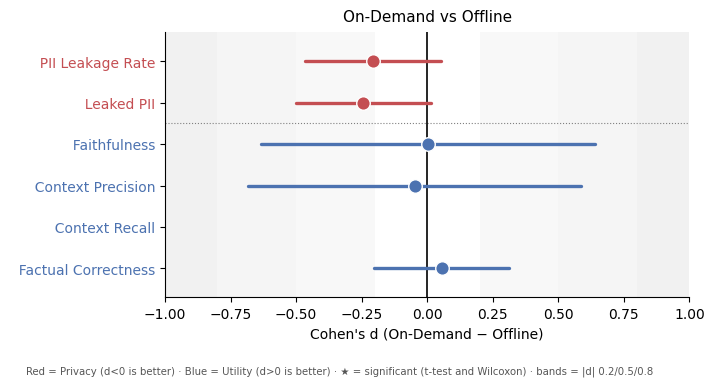

In [9]:
import matplotlib.pyplot as plt
import numpy as np


METRIC_DISPLAY_NAMES = {
    "leakage_rate": "PII Leakage Rate",
    "leaked_pii": "Leaked PII",
    "faithfulness": "Faithfulness",
    "context_precision": "Context Precision",
    "context_recall": "Context Recall",
    "factual_correctness": "Factual Correctness",
}
GROUPS = {
    "leakage_rate": "Privacy",
    "leaked_pii": "Privacy",
    "faithfulness": "Utility",
    "context_precision": "Utility",
    "context_recall": "Utility",
    "factual_correctness": "Utility",
}
GROUP_COLORS = {
    "Privacy": "#c44e52",
    "Utility": "#4c72b0",
}
ORDER = list(METRIC_DISPLAY_NAMES)

res_by_metric = results.set_index("metric")
rows = []
for col in ORDER:
    r = res_by_metric.loc[col]
    sd = paired_diffs(paired, col).std(ddof=1)
    ci_lo, ci_hi = r["ci_mean_diff_low"], r["ci_mean_diff_high"]
    if sd and not np.isnan(sd) and sd > 0:
        d_lo, d_hi = ci_lo / sd, ci_hi / sd
    else:
        d_lo = d_hi = np.nan
    rows.append({
        "label": METRIC_DISPLAY_NAMES[col],
        "group": GROUPS[col],
        "d": r["cohens_d"],
        "d_lo": d_lo,
        "d_hi": d_hi,
        "sig": bool(r["significant"]),
    })

ys = list(range(len(rows)))[::-1]
fig, ax = plt.subplots(figsize=(7.6, 3.9))

for lo, hi, alpha in [(0.2, 0.5, 0.05), (0.5, 0.8, 0.08), (0.8, 3.0, 0.11)]:
    for s in (1, -1):
        ax.axvspan(s * lo, s * hi, color="grey", alpha=alpha, lw=0, zorder=0)
ax.axvline(0.0, color="black", lw=1.2, zorder=1)

for yi, row in zip(ys, rows):
    color = GROUP_COLORS[row["group"]]
    if not (np.isnan(row["d_lo"]) or np.isnan(row["d_hi"])):
        ax.plot([row["d_lo"], row["d_hi"]], [yi, yi], color=color, lw=2.4,
                zorder=2, solid_capstyle="round")
    ax.scatter([row["d"]], [yi], color=color, edgecolor="white", s=95, lw=1.0, zorder=3)

ax.set_yticks(ys)
ax.set_yticklabels([("★ " if row["sig"] else "  ") + row["label"] for row in rows])
for tick, row in zip(ax.get_yticklabels(), rows):
    tick.set_color(GROUP_COLORS[row["group"]])
    if row["sig"]:
        tick.set_fontweight("bold")
ax.set_xlabel("Cohen's d (On-Demand − Offline)")
ax.axhline((ys[1] + ys[2]) / 2, color="grey", ls=":", lw=0.8, zorder=0)

alld = [v for row in rows for v in (row["d_lo"], row["d_hi"], row["d"]) if not np.isnan(v)]
lim = max(1.0, max(abs(min(alld)), abs(max(alld))) * 1.1)
ax.set_xlim(-lim, lim)
ax.margins(y=0.14)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)

ax.set_title("On-Demand vs Offline", fontsize=11, pad=8)
fig.text(
    0.5, 0.005,
    "Red = Privacy (d<0 is better) · Blue = Utility (d>0 is better) · "
    "★ = significant (t-test and Wilcoxon) · bands = |d| 0.2/0.5/0.8",
    fontsize=7.3, color="#555", ha="center",
)
fig.subplots_adjust(left=0.27, right=0.96, top=0.88, bottom=0.20)
plt.show()